#### The delay time distributions for WDWD and NSNS systems that merge within a Hubble Time

### Imports and definitions

In [1]:
import h5py as h5 
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import tol_colors as tc

import useful_fncs
import utils_from_others
import figure_utils

# plotting imports
# import for axes labels 
plt.rc('text.latex', preamble=r'\usepackage{textgreek}')
plt.rc('font', family='serif')
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif"
})

### Read in Data

Similarly to the formation efficiencies our systems of interest are those that merge in a Hubble Time and are 
1) two neutron stars (NSNS)
2) a carbon oyxygen white dwarf and any white dwarf (COWD+WD)

We will use the DCOmask filter to help us select for these systems, and then booleans to make further selections.
We will use the NSNS optimized run to analyze the delay time distribution for the NSNS systems, and the WDWD optimized run to look at the delay time distribution for the COWD+WD systems.

In [2]:
# let's read in our files for the fiducial case

## NSNS optimized run

# let's first look at the NSNS_output
pathToH5_NSNS = '/expanse/lustre/scratch/msantiago/temp_project/v03.21.00/COMPAS_DATA/v03.21.00/N5e6_NSNS_fid/MainRun/COMPAS_Output_wWeights.h5'

Data_NSNS  = h5.File(pathToH5_NSNS, "r")

DCOs_NSNS = Data_NSNS['BSE_Double_Compact_Objects'] # getting the DCO objects

# gathering the double compact objects that we have computed rates for
DCO_mask_NSNS = Data_NSNS['Rates_mu00.025_muz-0.049_alpha-1.79_sigma01.129_sigmaz0.048']['DCOmask'][()]

In [3]:
## gathering data
# merges in a Hubble Time
# times (these should be in Myr)
lifetimes_all = DCOs_NSNS['Time'][()]
lifetimes_DCO = lifetimes_all[DCO_mask_NSNS]

col_times_all = DCOs_NSNS['Coalescence_Time'][()]
col_times_DCO = col_times_all[DCO_mask_NSNS]

delay_times_all = lifetimes_all + col_times_all
# delay_times_DCO = lifetimes_DCO + col_times_DCO
condition_mergers = delay_times_all < 13800 # Myr

In [4]:
# masking for NSNS systems
stellar_types_all_1 = DCOs_NSNS['Stellar_Type(1)'][()]
# stellar_types_1_dco = stellar_types_all_1[DCO_mask_NSNS]
stellar_types_1_merged = stellar_types_all_1[condition_mergers]

stellar_types_all_2 = DCOs_NSNS['Stellar_Type(2)'][()]
# stellar_types_2_dco = stellar_types_all_2[DCO_mask_NSNS]
stellar_types_2_merged = stellar_types_all_2[condition_mergers]

# NSNS bool
NSNS_bool = np.logical_and(stellar_types_all_1==13, stellar_types_all_2==13)
# NSNS_systems_bool_all = np.logical_and(stellar_types_1_dco==13, stellar_types_2_dco==13)
NSNS_systems_bool_merged = np.logical_and(stellar_types_1_merged==13, stellar_types_2_merged==13)

In [5]:
# gathering the mixture weight info
mixture_weights_DCO_all = DCOs_NSNS['mixture_weight'][()]
# mixture_weights_DCO = mixture_weights_DCO_all[DCO_mask_NSNS]
mixture_weights_NSNS = mixture_weights_DCO_all[NSNS_bool]
mixtrue_weights_merged = mixture_weights_DCO_all[condition_mergers]
mixture_weights_merged_NSNS = mixtrue_weights_merged[NSNS_systems_bool_merged]

# gathering the metallicity info
Metallicity_DCO_all = Data_NSNS['BSE_Double_Compact_Objects']['Metallicity@ZAMS(1)'][()]
# metallicity_dco_masked = Metallicity_DCO_all[DCO_mask_NSNS]
metallicity_NSNS = Metallicity_DCO_all[NSNS_bool]
metallicity_merged = Metallicity_DCO_all[condition_mergers]
metallicity_merged_NSNS = metallicity_merged[NSNS_systems_bool_merged]

delay_times_all_NSNS = delay_times_all[NSNS_bool]
delay_times_merged = delay_times_all[condition_mergers]
delay_times_merged_NSNS = delay_times_merged[NSNS_systems_bool_merged]

### Let's do the same for the WDWD optimized run

In [6]:
## WDWD optimized run

# let's first look at the NSNS_output
pathToH5_WDWD = '/expanse/lustre/scratch/msantiago/temp_project/v03.21.00/COMPAS_DATA/v03.21.00/N5e6_MassiveWDWD_NSNS_fid/MainRun/COMPAS_Output_wWeights.h5'

Data_WDWD  = h5.File(pathToH5_WDWD, "r")

DCOs_WDWD = Data_WDWD['BSE_Double_Compact_Objects'] # getting the DCO objects

# gathering the double compact objects that we have computed rates for
DCO_mask_WDWD = Data_WDWD['Rates_mu00.025_muz-0.049_alpha-1.79_sigma01.129_sigmaz0.048']['DCOmask'][()]

In [7]:
# merges in a Hubble Time
# times (these should be in Myr)

lifetimes_all_WDWD = DCOs_WDWD['Time'][()]
lifetimes_DCO_WDWD = lifetimes_all_WDWD[DCO_mask_WDWD]

col_times_all_WDWD = DCOs_WDWD['Coalescence_Time'][()]
col_times_DCO_WDWD = col_times_all_WDWD[DCO_mask_WDWD]

delay_times_all_WD = lifetimes_all_WDWD + col_times_all_WDWD
condition_mergers_WDopt = delay_times_all_WD < 13800

In [8]:
# masking for COWD+WD systems
stellar_types_all_1_WDopt = DCOs_WDWD['Stellar_Type(1)'][()]
# stellar_types_1_dco_WDopt = stellar_types_all_1_WDopt[DCO_mask_WDWD]
stellar_types_1_merged_WDopt = stellar_types_all_1_WDopt[condition_mergers_WDopt]

stellar_types_all_2_WDopt = DCOs_WDWD['Stellar_Type(2)'][()]
# stellar_types_2_dco_WDopt = stellar_types_all_2_WDopt[DCO_mask_WDWD]
stellar_types_2_merged_WDopt = stellar_types_all_2_WDopt[condition_mergers_WDopt]

# gathering the masses
mass_1_all = DCOs_WDWD['Mass(1)'][()]
# mass_1_dco = mass_1_all[DCO_mask_WDWD]
mass_1_merged = mass_1_all[condition_mergers_WDopt]

mass_2_all = DCOs_WDWD['Mass(2)'][()]
# mass_2_dco = mass_2_all[DCO_mask_WDWD]
mass_2_merged = mass_2_all[condition_mergers_WDopt]

# we are going to conditions that M1>M2 (not considering mass ratio reversal cases)
M1 = np.maximum(mass_1_merged, mass_2_merged)
M2 = np.minimum(mass_1_merged, mass_2_merged)

In [9]:
# WDWD bool with at least one COWD + COWD/HeWD
HeWD_bool_WDWD_all,COWD_bool_WDWD_all,ONeWD_bool_WDWD_all,HeCOWD_bool_WDWD_all,HeONeWD_bool_WDWD_all,COHeWD_bool_WDWD_all,COONeWD_bool_WDWD_all,ONeHeWD_bool_WDWD_all,ONeCOWD_bool_WDWD_all = useful_fncs.WD_BINARY_BOOLS(stellar_types_all_1_WDopt, stellar_types_all_2_WDopt)
carbon_oxygen_bool_WDWD_all_WDopt = np.logical_or(ONeWD_bool_WDWD_all,np.logical_or(COONeWD_bool_WDWD_all,np.logical_or(COHeWD_bool_WDWD_all,np.logical_or(COWD_bool_WDWD_all,HeCOWD_bool_WDWD_all))))


HeWD_bool_WDWD,COWD_bool_WDWD,ONeWD_bool_WDWD,HeCOWD_bool_WDWD,HeONeWD_bool_WDWD,COHeWD_bool_WDWD,COONeWD_bool_WDWD,ONeHeWD_bool_WDWD,ONeCOWD_bool_WDWD = useful_fncs.WD_BINARY_BOOLS(stellar_types_1_merged_WDopt, stellar_types_2_merged_WDopt)
carbon_oxygen_bool_WDWD_merged_WDopt = np.logical_or(ONeCOWD_bool_WDWD,np.logical_or(COONeWD_bool_WDWD,np.logical_or(COHeWD_bool_WDWD,np.logical_or(COWD_bool_WDWD,HeCOWD_bool_WDWD))))


# # COWD + COWD/HeWD with Mchan > 1.4
# tot_mass_cond = mass_1_merged + mass_2_merged > 1.4
# super_chan_bool = carbon_oxygen_bool_WDWD_merged_WDopt*tot_mass_cond

# # COWD + COWD 
# # violent merger - unequal mass + COWD+COWD
# mass_unequal_conditon = np.logical_and(M1 >= 1.1, M2!=M1)
# violent_merger_unequal_bool = mass_unequal_conditon*COWD_bool

# # violent merger - equal mass (q_cr = 0.9) + COWD+COWD
# mass_min_criteria = M1>=0.8
# critical_mass_ratio_bool = np.logical_and(M2/M1 >= 0.9, mass_min_criteria)
# violent_merger_equal_bool = critical_mass_ratio_bool*COWD_bool

# # D6 HVS
# SN_Ia_HVS,two_star_SNIA,Champagne_Supernova = useful_fncs.check_if_SNIA(mass_1_merged[carbon_oxygen_bool_WDWD_merged_WDopt], mass_2_merged[carbon_oxygen_bool_WDWD_merged_WDopt])

# # D6 - two explosion
# mass_D6_condition = mass_1_merged < 1.0
# d6_two_explosion = mass_D6_condition*carbon_oxygen_bool_WDWD_merged_WDopt

In [10]:
# delay time info for these masked systems
delay_time_all_DWD = delay_times_all_WD[carbon_oxygen_bool_WDWD_all_WDopt]
delay_time_WDopt_merged = delay_times_all_WD[condition_mergers_WDopt]
delay_times_WDopt_merged_DWD = delay_time_WDopt_merged[carbon_oxygen_bool_WDWD_merged_WDopt]

mixture_weights_WDopt_all = DCOs_WDWD['mixture_weight'][()]
mixture_weights_WDopt_DWD = mixture_weights_WDopt_all[carbon_oxygen_bool_WDWD_all_WDopt]
mixture_weights_WDopt_merged = mixture_weights_WDopt_all[condition_mergers_WDopt]
mixture_weights_WDopt_merged_DWD = mixture_weights_WDopt_merged[carbon_oxygen_bool_WDWD_merged_WDopt]

# gathering the metallicity info
Metallicity_DCO_all_WDopt = Data_WDWD['BSE_Double_Compact_Objects']['Metallicity@ZAMS(1)'][()]
# metallicity_dco_masked = Metallicity_DCO_all[DCO_mask_NSNS]
Metallicity_DCO_all_DWD = Metallicity_DCO_all_WDopt[carbon_oxygen_bool_WDWD_all_WDopt]
metallicity_merged_WDopt = Metallicity_DCO_all_WDopt[condition_mergers_WDopt]
metallicity_merged_DWD = metallicity_merged_WDopt[carbon_oxygen_bool_WDWD_merged_WDopt]


In [11]:
# delay_times_super_chan_WDopt = delay_times_merged_WDopt[super_chan_bool]
# mixture_weights_super_chan_WDWD_WDopt = mixture_weights_merged_WDopt[super_chan_bool]

# delay_times_violent_unequal = delay_times_merged_WDopt[violent_merger_unequal_bool]
# mixture_weights_violent_unequal = mixture_weights_merged_WDopt[violent_merger_unequal_bool]

# delay_times_violent_equal = delay_times_merged_WDopt[violent_merger_equal_bool]
# mixture_weights_violent_equal = mixture_weights_merged_WDopt[violent_merger_equal_bool]

# delay_times_HVS = delay_times_merged_WDopt[SN_Ia_HVS]
# mixture_weights_HVS = mixture_weights_merged_WDopt[SN_Ia_HVS]

# delay_times_D6_two = delay_times_merged_WDopt[d6_two_explosion]
# mixture_weights_D6_two = mixture_weights_merged_WDopt[d6_two_explosion]

### Plotting!

### First let's plot the delay time distirbution without any weighting by formation efficencies

Text(0.5, 1.0, 'Delay Time Distributions: All BNS')

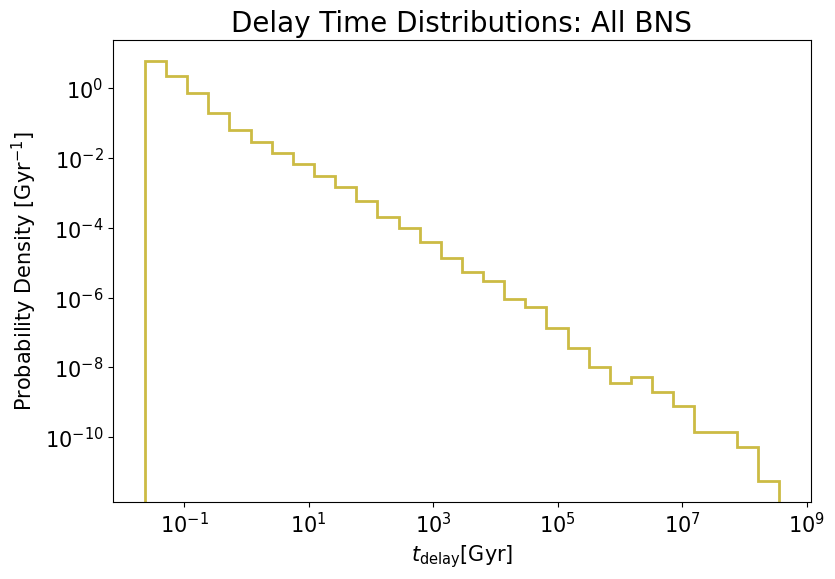

In [12]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright


# NSNS
delay_times_all_NSNS_Gyr = delay_times_all_NSNS*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_all_NSNS_Gyr.min()), np.log10(delay_times_all_NSNS_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
n_per_bin, _ = np.histogram(delay_times_all_NSNS_Gyr, bins=edges_check, weights = mixture_weights_NSNS, density=True) # density = True to make a probability density, units = Gyr^-1

axs.stairs(n_per_bin, edges_check, color=cset_br.yellow, lw=2, label="simulated binaries per bin (all 5 million)")

axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}]$', fontsize=15)
# axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: All BNS', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

Text(0.5, 1.0, 'Delay Time Distributions: BNS Merged')

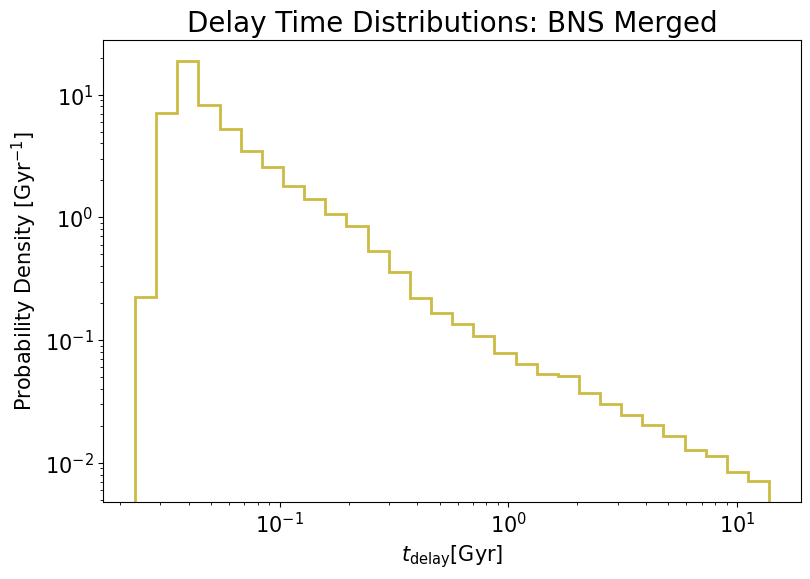

In [13]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright


# NSNS
delay_times_merged_NSNS_Gyr = delay_times_merged_NSNS*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_merged_NSNS_Gyr.min()), np.log10(delay_times_merged_NSNS_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
n_per_bin, _ = np.histogram(delay_times_merged_NSNS_Gyr, bins=edges_check, weights = mixture_weights_merged_NSNS, density=True) # density = True to make a probability density, units = Gyr^-1

axs.stairs(n_per_bin, edges_check, color=cset_br.yellow, lw=2)

axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}]$', fontsize=15)
# axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: BNS Merged', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/DTD_BNS_merged_log.png",bbox_inches='tight',pad_inches=0.1)

#### Now the DWD systems

Text(0.5, 1.0, 'Delay Time Distributions: All DWD')

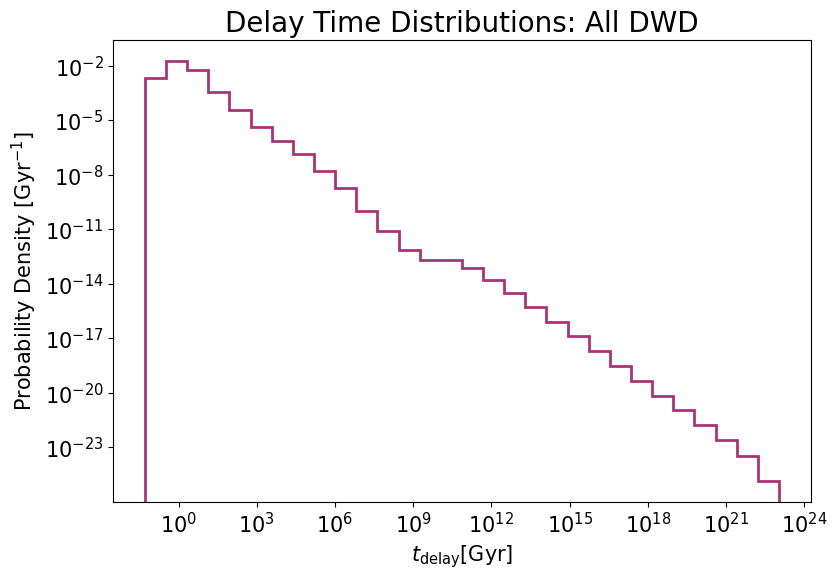

In [14]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright

# NSNS
delay_times_all_DWD_Gyr = delay_time_all_DWD*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_all_DWD_Gyr.min()), np.log10(delay_times_all_DWD_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
n_per_bin, _ = np.histogram(delay_times_all_DWD_Gyr, bins=edges_check, weights=mixture_weights_WDopt_DWD, density=True) # density = True to make a probability density, units = Gyr^-1

axs.stairs(n_per_bin, edges_check, color=cset_br.purple, lw=2, label="simulated binaries per bin (all 5 million)")

axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}]$', fontsize=15)
# axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: All DWD', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

Text(0.5, 1.0, 'Delay Time Distributions: Merging DWD')

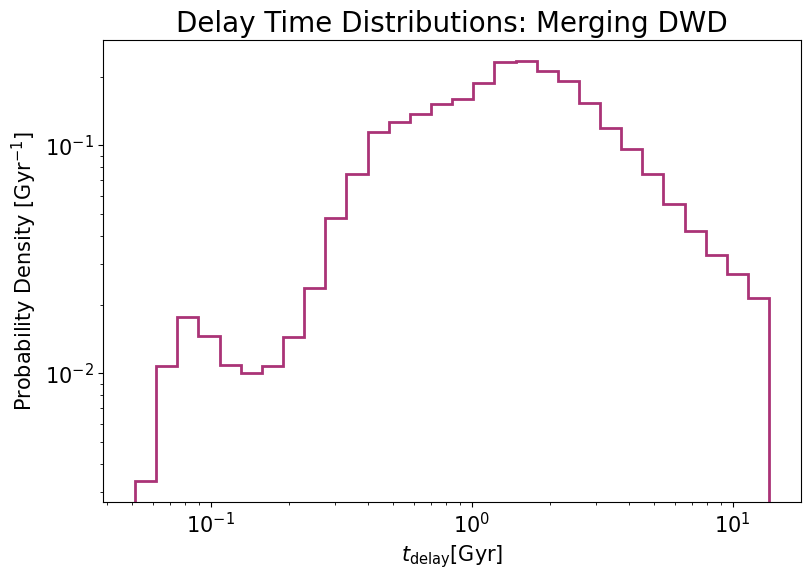

In [15]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright

# NSNS
delay_times_all_DWD_Gyr = delay_times_WDopt_merged_DWD*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_all_DWD_Gyr.min()), np.log10(delay_times_all_DWD_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
n_per_bin, _ = np.histogram(delay_times_all_DWD_Gyr, bins=edges_check, weights=mixture_weights_WDopt_merged_DWD, density=True) # density = True to make a probability density, units = Gyr^-1

axs.stairs(n_per_bin, edges_check, color=cset_br.purple, lw=2, label="simulated binaries per bin (all 5 million)")

axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}]$', fontsize=15)
# axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: Merging DWD', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

### Let's find the formation effiency per system!

In [16]:
def mass_formed_per_bin(log_z_edges, M_SIM, DLOGZ_TOT):
    '''Star-forming mass represented by the simulation in each log10(Z) bin (flat-in-log sampling).'''
    return M_SIM * np.diff(log_z_edges) / DLOGZ_TOT

In [17]:
# let's find the minimum mass
mass_1 = Data_NSNS['BSE_System_Parameters']['Mass@ZAMS(1)'][()]
mass_2 = Data_NSNS['BSE_System_Parameters']['Mass@ZAMS(2)'][()]
m1min_NSNS = min(mass_1)
m1max_NSNS = max(mass_1)
m2min_NSNS = min(mass_2)
print(m1min_NSNS, m1max_NSNS, m2min_NSNS)

# let's use the information above to fins the average star forming mass per binary

m_rep_per_binary = utils_from_others.analytical_star_forming_mass_per_binary_using_kroupa_imf(5, 150, 0.1, 0.7)

Z_all_NSNS = Data_NSNS['BSE_System_Parameters']['Metallicity@ZAMS(1)'][()]
n_binaries = len(Z_all_NSNS)
print(n_binaries)
total_mass_evolved_compas = n_binaries * m_rep_per_binary
print(total_mass_evolved_compas, ' [Msun]')

5.000001680589246 149.99884771208616 0.10000205410485367
Integrating from 0.01 to 0.08 for fbin = 0.7 and exponent = -0.3
Integrating from 0.08 to 0.5 for fbin = 0.7 and exponent = -1.3
Integrating from 0.5 to 1 for fbin = 0.7 and exponent = -2.3
Integrating from 1 to 10 for fbin = 0.7 and exponent = -2.3
Integrating from 10 to 200 for fbin = 0.7 and exponent = -2.3
5000000
508565253.5816714  [Msun]


In [18]:
N_Z_BINS = 50                                  # fine enough to resolve eta(Z), coarse enough for good statistics

LOG_Z_MIN, LOG_Z_MAX = np.log10(Z_all_NSNS.min()), np.log10(Z_all_NSNS.max())
LOG_Z_EDGES = np.linspace(LOG_Z_MIN, LOG_Z_MAX, N_Z_BINS + 1) # this is in linspace so the digitize and clipping works correctly 
DLOGZ_TOT = LOG_Z_MAX - LOG_Z_MIN

mass_per_bin = mass_formed_per_bin(LOG_Z_EDGES, total_mass_evolved_compas, DLOGZ_TOT)

# first let's look at just all BNS, not just merged ones
z_bin_NSNS = np.clip(np.digitize(np.log10(metallicity_NSNS), LOG_Z_EDGES) - 1, 0, N_Z_BINS - 1)
eta_NSNS = mixture_weights_NSNS/mass_per_bin[z_bin_NSNS]

# now just those that have merged
z_bin_NSNS_merged = np.clip(np.digitize(np.log10(metallicity_merged_NSNS), LOG_Z_EDGES) - 1, 0, N_Z_BINS - 1)
eta_NSNS_merged = mixture_weights_merged_NSNS/mass_per_bin[z_bin_NSNS_merged]

In [19]:
# consistency check: the bin-weighted mean of eta_i must equal sum(w)/M_sim
frac_of_range = np.diff(LOG_Z_EDGES) / DLOGZ_TOT
eta_mean_from_array = np.sum(eta_NSNS)*frac_of_range

eta_bns_mean_NSNS = np.sum(mixture_weights_NSNS)/total_mass_evolved_compas

print(f"mean eta from the per-binary values : {eta_mean_from_array[0]:.4e} per Msun")
print(f"mean eta from sum(w)/M_sim  (§1.4)  : {eta_bns_mean_NSNS:.4e} per Msun")
print(f"\nper-binary eta ranges from {eta_NSNS.min():.1e} to {eta_NSNS.max():.1e} per Msun (mean {np.median(eta_NSNS):.1e})")

mean eta from the per-binary values : 2.4931e-06 per Msun
mean eta from sum(w)/M_sim  (§1.4)  : 2.4931e-06 per Msun

per-binary eta ranges from 1.3e-10 to 1.3e-07 per Msun (mean 3.5e-10)


#### Now for the DWD systems

In [20]:
# let's find the minimum mass
mass_1_WDWD = Data_WDWD['BSE_System_Parameters']['Mass@ZAMS(1)'][()]
mass_2_WDWD = Data_WDWD['BSE_System_Parameters']['Mass@ZAMS(2)'][()]
m1min_WDWD = min(mass_1_WDWD)
m1max_WDWD = max(mass_1_WDWD)
m2min_WDWD = min(mass_2_WDWD)
print(m1min_WDWD, m1max_WDWD, m2min_WDWD)

# let's use the information above to fins the average star forming mass per binary
m_rep_per_binary_WDWD = utils_from_others.analytical_star_forming_mass_per_binary_using_kroupa_imf(1, 150, 0.1, 0.7)

print('1 binary in COMPAS WDWD opimized run represents', m_rep_per_binary_WDWD, ' solar masses formed')

# now calculate the number of binaries in COMPAS simulation (over the entire simulation)
Z_all_DWD = Data_WDWD['BSE_System_Parameters']['Metallicity@ZAMS(1)'][()]
n_binaries_WDWD = len(Z_all_DWD)
print(n_binaries_WDWD)

total_mass_evolved_compas_WDWD = n_binaries_WDWD * m_rep_per_binary_WDWD
print(total_mass_evolved_compas_WDWD, ' [Msun]')

1.0000013114546709 149.84690074731307 0.10001294195257501
Integrating from 0.01 to 0.08 for fbin = 0.7 and exponent = -0.3
Integrating from 0.08 to 0.5 for fbin = 0.7 and exponent = -1.3
Integrating from 0.5 to 1 for fbin = 0.7 and exponent = -2.3
Integrating from 1 to 10 for fbin = 0.7 and exponent = -2.3
Integrating from 10 to 200 for fbin = 0.7 and exponent = -2.3
1 binary in COMPAS WDWD opimized run represents 13.014304811861441  solar masses formed
5000000
65071524.0593072  [Msun]


In [21]:
N_Z_BINS_DWD = 50                                  # fine enough to resolve eta(Z), coarse enough for good statistics

LOG_Z_MIN_DWD, LOG_Z_MAX_DWD = np.log10(Z_all_DWD.min()), np.log10(Z_all_DWD.max())
LOG_Z_EDGES_DWD = np.linspace(LOG_Z_MIN_DWD, LOG_Z_MAX_DWD, N_Z_BINS_DWD + 1)
DLOGZ_TOT_DWD = LOG_Z_MAX_DWD - LOG_Z_MIN_DWD

mass_per_bin_DWD = mass_formed_per_bin(LOG_Z_EDGES_DWD, total_mass_evolved_compas_WDWD, DLOGZ_TOT_DWD)

# first let's look at just all BNS, not just merged ones
z_bin_DWD = np.clip(np.digitize(np.log10(Metallicity_DCO_all_DWD), LOG_Z_EDGES_DWD) - 1, 0, N_Z_BINS_DWD - 1)
eta_DWD = mixture_weights_WDopt_DWD/mass_per_bin_DWD[z_bin_DWD]

# now just those that have merged
z_bin_DWD_merged = np.clip(np.digitize(np.log10(metallicity_merged_DWD), LOG_Z_EDGES_DWD) - 1, 0, N_Z_BINS_DWD - 1)
eta_DWD_merged = mixture_weights_WDopt_merged_DWD/mass_per_bin[z_bin_DWD_merged]

In [22]:
# consistency check: the bin-weighted mean of eta_i must equal sum(w)/M_sim
frac_of_range = np.diff(LOG_Z_EDGES_DWD) / DLOGZ_TOT_DWD
eta_mean_from_array = np.sum(eta_DWD)*frac_of_range

eta_bns_mean_DWD = np.sum(mixture_weights_WDopt_merged_DWD)/total_mass_evolved_compas_WDWD

print(f"mean eta from the per-binary values : {eta_mean_from_array[0]:.4e} per Msun")
print(f"mean eta from sum(w)/M_sim  (§1.4)  : {eta_bns_mean_DWD:.4e} per Msun")
print(f"\nper-binary eta ranges from {eta_DWD.min():.1e} to {eta_DWD.max():.1e} per Msun (mean {np.median(eta_DWD):.1e})")


mean eta from the per-binary values : 2.5557e-02 per Msun
mean eta from sum(w)/M_sim  (§1.4)  : 2.6946e-03 per Msun

per-binary eta ranges from 1.2e-08 to 1.0e-05 per Msun (mean 3.2e-08)


### Plotting with the systems weighed by their formation efficencies

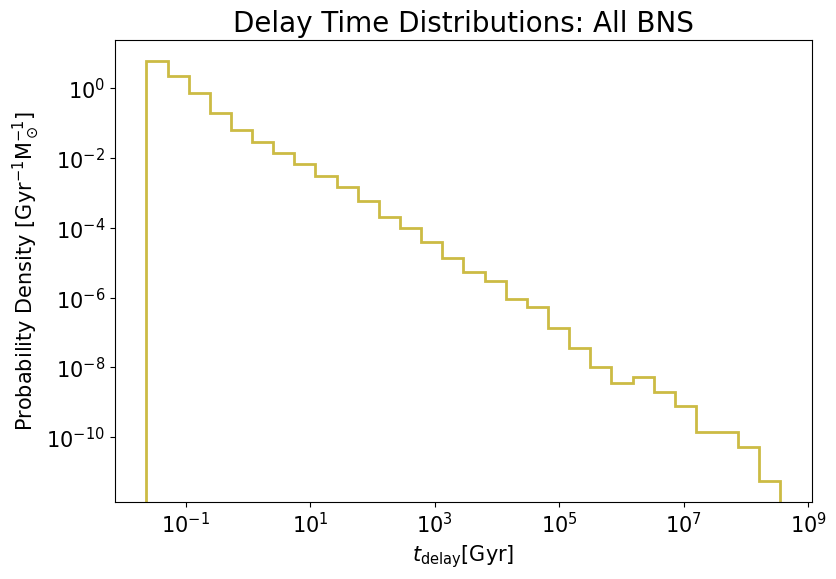

In [23]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright


# NSNS
delay_times_all_NSNS_Gyr = delay_times_all_NSNS*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_all_NSNS_Gyr.min()), np.log10(delay_times_all_NSNS_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
# since dnesity= True this is probability density meaning it is delta N/ delat t_delay / N_tot
n_per_bin, _ = np.histogram(delay_times_all_NSNS_Gyr, bins=edges_check, weights = eta_NSNS, density=True) # density = True to make a probability density, units = Gyr^-1

axs.stairs(n_per_bin, edges_check, color=cset_br.yellow, lw=2, label="simulated binaries per bin (all 5 million)")

axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}\mathrm{M}_\odot^{-1}]$', fontsize=15)
# axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: All BNS', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

Text(0.5, 1.0, 'Delay Time Distributions: BNS Merged')

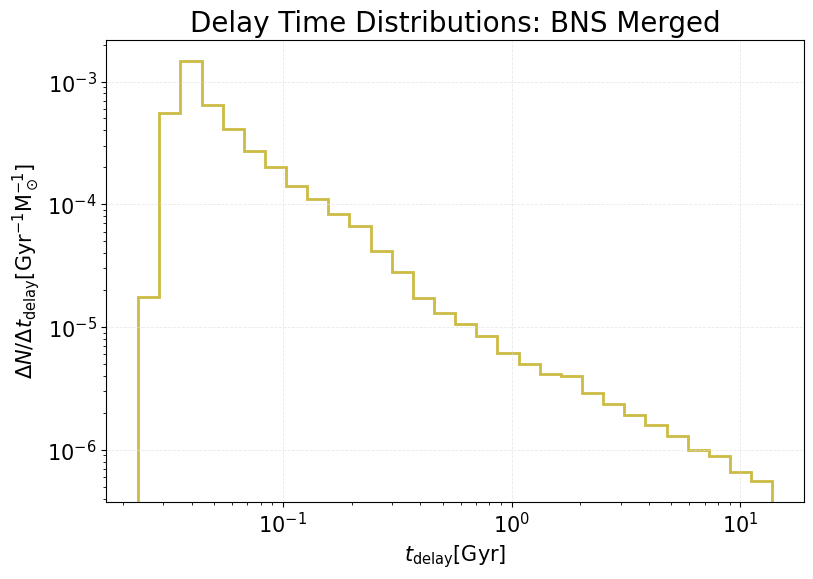

In [28]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright

axs.grid(True, color='#e0e0e0', linestyle='--', linewidth=0.6, alpha=0.7)


# NSNS
delay_times_merged_NSNS_Gyr = delay_times_merged_NSNS*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_merged_NSNS_Gyr.min()), np.log10(delay_times_merged_NSNS_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
n_per_bin, _ = np.histogram(delay_times_merged_NSNS_Gyr, bins=edges_check, weights = eta_NSNS_merged, density=False) 

# with denisty=False, need to divide by the bin width 
axs.stairs(n_per_bin/np.diff(edges_check), edges_check, color=cset_br.yellow, lw=2)

axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} t_{\mathrm{delay}} [\mathrm{Gyr^{-1}}\mathrm{M}_\odot^{-1}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
# axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}\mathrm{M}_\odot^{-1}]$', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: BNS Merged', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/DTD_BNS_merged_eta_log.png",bbox_inches='tight',pad_inches=0.1)

Text(0.5, 1.0, 'Delay Time Distributions: Merging DWD')

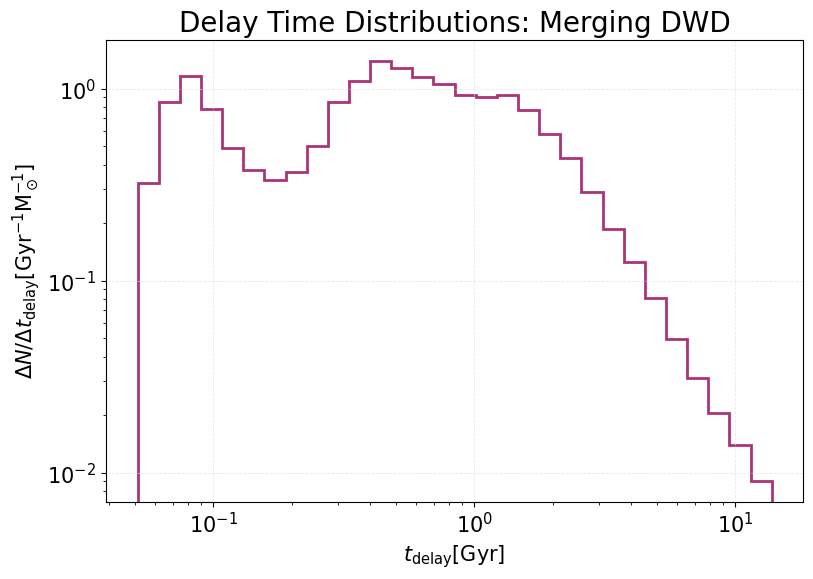

In [31]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(9, 6))

cset_br = tc.bright

axs.grid(True, color='#e0e0e0', linestyle='--', linewidth=0.6, alpha=0.7)

# NSNS
delay_times_all_DWD_Gyr = delay_times_WDopt_merged_DWD*(10**-3)

DELAY_T_MIN, DELAY_T_MAX = np.log10(delay_times_all_DWD_Gyr.min()), np.log10(delay_times_all_DWD_Gyr.max())

nbins = 30
edges_check = np.logspace(DELAY_T_MIN, DELAY_T_MAX, nbins + 1)
n_per_bin, _ = np.histogram(delay_times_all_DWD_Gyr, bins=edges_check, weights=eta_DWD_merged, density=True) # density = True to make a probability density, units = Gyr^-1

axs.stairs(n_per_bin/np.diff(edges_check), edges_check, color=cset_br.purple, lw=2, label="simulated binaries per bin (all 5 million)")

# axs.set_ylabel(r'Probability Density [$\mathrm{Gyr}^{-1}\mathrm{M}_\odot^{-1}]$', fontsize=15)
axs.set_ylabel(r"$\mathrm{\Delta} N/\mathrm{\Delta} t_{\mathrm{delay}} [\mathrm{Gyr^{-1}}\mathrm{M}_\odot^{-1}]$", fontsize=15)# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
# axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions: Merging DWD', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/DTD_DWD_merged_eta_log.png",bbox_inches='tight',pad_inches=0.1)

NameError: name 'delay_time_NSNS_all' is not defined

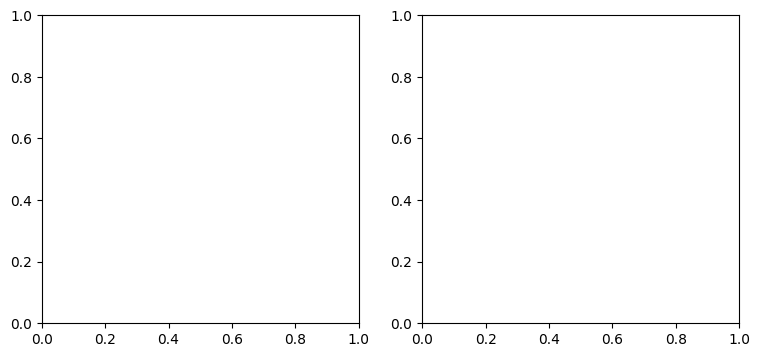

In [24]:
### plotting delay time dist
fig, axs = plt.subplots(1,2, figsize=(9, 4))

cset = tc.pale
cset_c = tc.medium_contrast

# bins_logspace = np.logspace(min(np.log(delay_time_NSNS_all)), max(np.log(delay_time_NSNS_all)), 40)

# NSNS
hist, bin_edges = np.histogram(delay_time_NSNS_all, weights=mixture_weights_NSNS_all, bins=40, density=False)

bin_centers = (bin_edges[0:-1] + bin_edges[1:])/2
bin_widths = np.diff(bin_edges)

axs[0].plot(bin_centers, (hist/bin_widths), color=cset.pale_green, lw=3, label='NSNS merged')
axs[0].vlines(x=[13800], ymin=0, ymax=10**0, colors=cset_c.dark_blue, ls='--', lw=2) # vertical line

# plt.yscale('log')
# plt.ylim(10**-8, 10**-5)

# adding a line for hubbble time


# axs[0].set_ylabel(r'$\mathrm{dN/d}\log_{10}(T_{\mathrm{delay}}(\mathrm{Myr}))$', fontsize=15)
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_xlabel(r'$t_{\mathrm{delay}}[Myr^{-1}]$', fontsize=15)
# axs[0].xaxis.grid(True, which='minor', alpha=0.7)
axs[0].set_ylabel(r'$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Myr^{-1}}]$', fontsize=15)

axs[0].legend()

# COWD+WD
hist_WDWD_WDopt, bin_edges_WDWD_WDopt = np.histogram(delay_time_WDWD_WDopt_all, weights=mixture_weights_WDWD_WDopt_all, bins=40, density=False)

bin_centers_WDWD_WDopt = (bin_edges_WDWD_WDopt[0:-1] + bin_edges_WDWD_WDopt[1:])/2
bin_wdiths_WDopt = np.diff(bin_edges_WDWD_WDopt)

axs[1].plot(bin_centers_WDWD_WDopt, hist_WDWD_WDopt/bin_wdiths_WDopt, color=cset.pale_blue, lw=3, label='COWD+WD merged')

# axs[1].set_ylabel(r'$dN/d\log_{10}(T_{\mathrm{delay}}(\mathrm{Myr}))$', fontsize=15)
axs[1].set_xlabel(r'$t_{\mathrm{delay}}[Myr^{-1}]$', fontsize=15)
# axs[1].xaxis.grid(True, which='minor', alpha=0.7)
axs[1].set_xscale('log')
axs[1].set_yscale('log')
axs[1].legend(loc='lower left')

fig.suptitle('Delay Time Distributions')

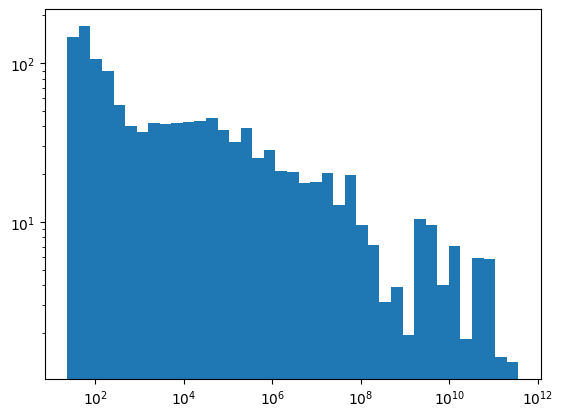

In [65]:
log_bins = np.logspace(np.log10(min(delay_time_NSNS_all)), np.log10(max(delay_time_NSNS_all)), 40)
plt.hist(delay_time_NSNS_all, weights = mixture_weights_NSNS_all, bins = log_bins);
plt.xscale('log')
plt.yscale('log')

### Then let's look at the systems that have merged

Text(0.5, 0.98, 'Delay Time Distributions')

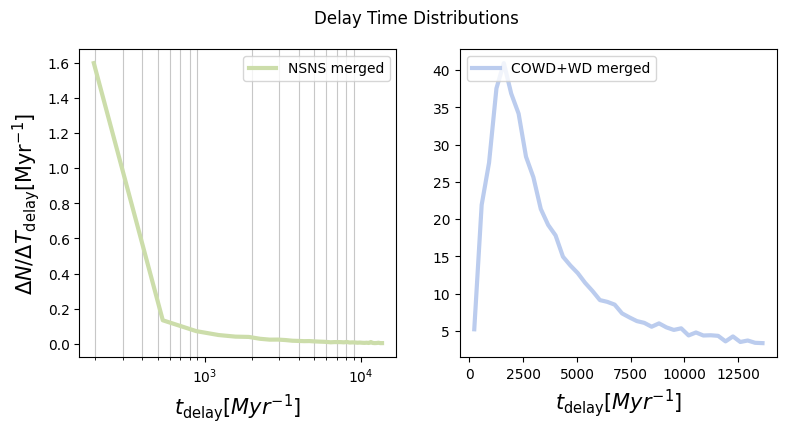

In [58]:
# plotting delay time dist
fig, axs = plt.subplots(1,2, figsize=(9, 4))

cset = tc.pale

# bins_logspace = np.logspace(min(np.log(delay_times_merged_NSNS)), max(np.log(delay_times_merged_NSNS)), 40)

# NSNS
hist, bin_edges = np.histogram(delay_times_merged_NSNS, weights=mixture_weights_merged_NSNS, bins=40, density=False)

bin_centers = (bin_edges[0:-1] + bin_edges[1:])/2
bin_widths = np.diff(bin_edges)

axs[0].plot(bin_centers, (hist/bin_widths), color=cset.pale_green, lw=3, label='NSNS merged')

# plt.yscale('log')
# plt.ylim(10**-8, 10**-5)

# axs[0].set_ylabel(r'$\mathrm{dN/d}\log_{10}(T_{\mathrm{delay}}(\mathrm{Myr}))$', fontsize=15)
axs[0].set_xscale('log')
axs[0].set_xlabel(r'$t_{\mathrm{delay}}[Myr^{-1}]$', fontsize=15)
axs[0].xaxis.grid(True, which='minor', alpha=0.7)
axs[0].set_ylabel(r'$\mathrm{\Delta} N/\mathrm{\Delta} T_{\mathrm{delay}} [\mathrm{Myr^{-1}}]$', fontsize=15)

axs[0].legend()

# COWD+WD
hist_WDWD_WDopt, bin_edges_WDWD_WDopt = np.histogram(delay_times_merged_WDWD_WDopt, weights=mixture_weights_merged_WDWD_WDopt, bins=40, density=False)

bin_centers_WDWD_WDopt = (bin_edges_WDWD_WDopt[0:-1] + bin_edges_WDWD_WDopt[1:])/2
bin_wdiths_WDopt = np.diff(bin_edges_WDWD_WDopt)

axs[1].plot(bin_centers_WDWD_WDopt, hist_WDWD_WDopt/bin_wdiths_WDopt, color=cset.pale_blue, lw=3, label='COWD+WD merged')

# axs[1].set_ylabel(r'$dN/d\log_{10}(T_{\mathrm{delay}}(\mathrm{Myr}))$', fontsize=15)
axs[1].set_xlabel(r'$t_{\mathrm{delay}}[Myr^{-1}]$', fontsize=15)
axs[1].xaxis.grid(True, which='minor', alpha=0.7)
axs[1].legend(loc='upper left')

fig.suptitle('Delay Time Distributions')

In [55]:
# # plotting delay time dist
# fig, axs = plt.subplots(figsize=(8, 6))

# cset = tc.dark
# cset_l = tc.light

# # COWD+WD
# bins_WDWD = np.arange(0,20,2)

# delay_times_merged_WDWD_WDopt_Gyr = delay_times_merged_WDWD_WDopt*(10**-3)
# hist_WDWD_WDopt, bin_edges_WDWD_WDopt = np.histogram(delay_times_merged_WDWD_WDopt_Gyr, weights=mixture_weights_merged_WDWD_WDopt, bins=bins_WDWD, density=False)

# binwidth_WDWD = np.diff(bins_WDWD)
# bin_centers_WDWD_WDopt = (bin_edges_WDWD_WDopt[0:-1] + bin_edges_WDWD_WDopt[1:])/2

# axs.plot(bin_centers_WDWD_WDopt, (hist_WDWD_WDopt/binwidth_WDWD), color=cset.dark_blue, lw=3, label='COWD+WD merged')


# # COWD+WD M_tot>1.4

# delay_times_super_chan_WDWD_WDopt_Gyr = delay_times_super_chan_WDopt*(10**-3)
# hist_WDWD_WDopt_super_chan, bin_edges_WDWD_WDopt_super_chan = np.histogram(delay_times_super_chan_WDWD_WDopt_Gyr, weights=mixture_weights_super_chan_WDWD_WDopt, bins=bins_WDWD, density=False)

# binwidth_WDWD = np.diff(bins_WDWD)
# bin_centers_WDWD_WDopt_super_chan = (bin_edges_WDWD_WDopt_super_chan[0:-1] + bin_edges_WDWD_WDopt_super_chan[1:])/2

# axs.plot(bin_centers_WDWD_WDopt_super_chan, (hist_WDWD_WDopt_super_chan/binwidth_WDWD), color=cset_l.orange,label=r'COWD+WD merged: $\rm{M_{TOT}}>1.4\rm{M_{\odot}}$')

# # # D^6 - two star explosion

# # bins_WDWD_D6_two = np.arange(0,20,2)

# # delay_times_D6_two_Gyr = delay_times_D6_two*(10**-3)
# # hist_D6_two, bin_edges_D6_two = np.histogram(delay_times_D6_two_Gyr, weights=mixture_weights_D6_two, bins=bins_WDWD_D6_two, density=False)

# # binwidth_D6_two = np.diff(bins_WDWD_D6_two)
# # bin_centers_D6_two = (bin_edges_D6_two[0:-1] + bin_edges_D6_two[1:])/2

# # axs.plot(bin_centers_D6_two, (hist_D6_two/binwidth_D6_two), color=cset_l.light_blue, lw=2, ls='--', label='$\mathrm{D^6}$ Quadrupole Degenerate')


# # # violent merger - unequal

# # bins_WDWD_vm_unequal = np.arange(0,20,2)

# # delay_times_violent_unequal_Gyr = delay_times_violent_unequal*(10**-3)
# # hist_vm_unequal, bin_edges_vm_unequal = np.histogram(delay_times_violent_unequal_Gyr, weights=mixture_weights_violent_unequal, bins=bins_WDWD_vm_unequal, density=False)

# # binwidth_vm_unequal = np.diff(bins_WDWD_vm_unequal)
# # bin_centers_vm_unequal = (bin_edges_vm_unequal[0:-1] + bin_edges_vm_unequal[1:])/2

# # axs.plot(bin_centers_vm_unequal, (hist_vm_unequal/binwidth_vm_unequal), color=cset_l.orange, lw=2, label='Violent Merger - Unequal')

# # D^6 HVS

# bins_WDWD_HVS = np.arange(0,20,2)

# delay_times_HVS_Gyr = delay_times_HVS*(10**-3)
# hist_HVS, bin_edges_HVS = np.histogram(delay_times_HVS_Gyr, weights=mixture_weights_HVS, bins=bins_WDWD_HVS, density=False)

# binwidth_HVS = np.diff(bins_WDWD_HVS)
# bin_centers_HVS = (bin_edges_HVS[0:-1] + bin_edges_HVS[1:])/2

# axs.plot(bin_centers_HVS, (hist_HVS/binwidth_HVS), color=cset_l.light_yellow, lw=2, label='$\mathrm{D^6}$ HVS')


# # # violent merger - equal

# # bins_WDWD_vm_equal = np.arange(0,20,2)

# # delay_times_violent_equal_Gyr = delay_times_violent_equal*(10**-3)
# # hist_vm_equal, bin_edges_vm_equal = np.histogram(delay_times_violent_equal_Gyr, weights=mixture_weights_violent_equal, bins=bins_WDWD_vm_equal, density=False)

# # binwidth_vm_equal = np.diff(bins_WDWD_vm_equal)
# # bin_centers_vm_equal = (bin_edges_vm_equal[0:-1] + bin_edges_vm_equal[1:])/2

# # axs.plot(bin_centers_vm_equal, (hist_vm_equal/binwidth_vm_equal), color=cset_l.mint, lw=2, label='Violent Merger - Equal')






# axs.set_ylabel(r'$\mathrm{\Delta} N/\mathrm{\Delta} t_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$', fontsize=18)
# # axs[0].set_ylabel(r'Counts', fontsize=15)
# axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=18)
# axs.tick_params(axis='both', labelsize=15)
# axs.legend()

# axs.set_yscale('log')
# axs.set_xscale('log')
# # axs.legend(loc='upper left')

# axs.set_title('Delay Time Distributions', fontsize=20)

# # plt.subplots_adjust(wspace=0.4) # add padding between plots

# ## save figure:
# # plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

#### Counts weighted by the formation efficiencies

We can also weight the x axis by the formation efficiences

### Getting the formation efficiences

In [70]:
### first for the NSNS optimized run
# let's find the minimum mass

DATA_SPS = Data_NSNS['BSE_System_Parameters']

mass_1 = DATA_SPS['Mass@ZAMS(1)'][()]
mass_2 = DATA_SPS['Mass@ZAMS(2)'][()]
m1min_NSNS = min(mass_1)
m1max_NSNS = max(mass_1)
m2min_NSNS = min(mass_2)
print(m1min_NSNS, m1max_NSNS, m2min_NSNS)

5.000001680589246 149.99884771208616 0.10000205410485367


In [71]:
m_rep_per_binary = utils_from_others.analytical_star_forming_mass_per_binary_using_kroupa_imf(5, 150, 0.1, 0.7)
n_binaries = np.shape(Data_NSNS['BSE_System_Parameters']['SEED'][()])[0]

total_mass_evolved_compas = n_binaries * m_rep_per_binary

Integrating from 0.01 to 0.08 for fbin = 0.7 and exponent = -0.3
Integrating from 0.08 to 0.5 for fbin = 0.7 and exponent = -1.3
Integrating from 0.5 to 1 for fbin = 0.7 and exponent = -2.3
Integrating from 1 to 10 for fbin = 0.7 and exponent = -2.3
Integrating from 10 to 200 for fbin = 0.7 and exponent = -2.3


In [65]:
formation_efficiencies_NSNS_all = mixture_weights_NSNS_all/total_mass_evolved_compas # changed to all systems not dco

formation_efficiencies_NSNS_all = mixture_weights_NSNS_all/total_mass_evolved_compas
formation_efficiencies_NSNS_merged = mixture_weights_merged_NSNS/total_mass_evolved_compas

In [66]:
### now the WDWD opimitized case

DATA_SPS_WDWD = Data_WDWD['BSE_System_Parameters']

# let's find the minimum mass
mass_1_WDWD = DATA_SPS_WDWD['Mass@ZAMS(1)'][()]
mass_2_WDWD = DATA_SPS_WDWD['Mass@ZAMS(2)'][()]
m1min_WDWD = min(mass_1_WDWD)
m1max_WDWD = max(mass_1_WDWD)
m2min_WDWD = min(mass_2_WDWD)
print(m1min_WDWD, m1max_WDWD, m2min_WDWD)

1.0000013114546709 149.84690074731307 0.10001294195257501


In [67]:
m_rep_per_binary_WDWD = utils_from_others.analytical_star_forming_mass_per_binary_using_kroupa_imf(1, 150, 0.1, 0.7)
n_binaries_WDWD = np.shape(Data_WDWD['BSE_System_Parameters']['SEED'][()])[0]

total_mass_evolved_compas_WDWD = n_binaries_WDWD * m_rep_per_binary_WDWD

Integrating from 0.01 to 0.08 for fbin = 0.7 and exponent = -0.3
Integrating from 0.08 to 0.5 for fbin = 0.7 and exponent = -1.3
Integrating from 0.5 to 1 for fbin = 0.7 and exponent = -2.3
Integrating from 1 to 10 for fbin = 0.7 and exponent = -2.3
Integrating from 10 to 200 for fbin = 0.7 and exponent = -2.3


In [68]:
# formation efficiencies 
formation_efficiencies_COWD_WDopt_all = mixture_weights_WDWD_WDopt_all/total_mass_evolved_compas_WDWD
formation_efficiencies_COWD_WDopt = mixture_weights_merged_WDWD_WDopt/total_mass_evolved_compas_WDWD

# formation_efficiencies_super_chan_WDopt = mixture_weights_super_chan_WDWD_WDopt/total_mass_evolved_compas_WDWD

# formation_eff_violent_merger_unequal = mixture_weights_violent_unequal/total_mass_evolved_compas_WDWD

# formation_eff_violent_merger_equal= mixture_weights_violent_equal/total_mass_evolved_compas_WDWD

# formation_eff_HVS = mixture_weights_HVS/total_mass_evolved_compas_WDWD

# formation_eff_D6_two = mixture_weights_D6_two/total_mass_evolved_compas_WDWD

## Plotting again!

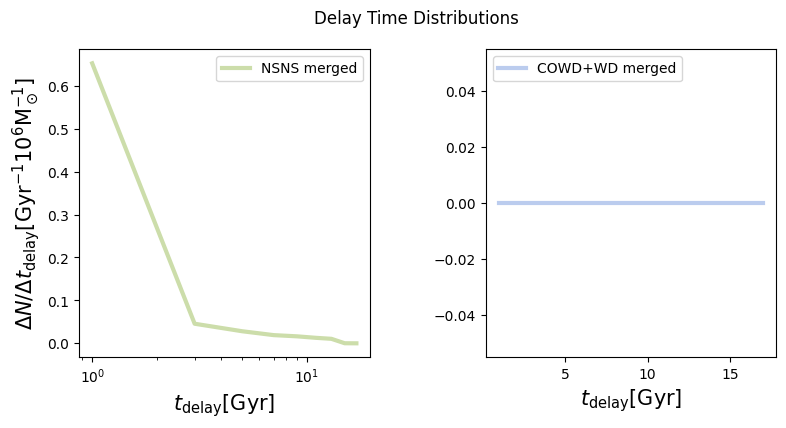

In [70]:
# plotting delay time dist
fig, axs = plt.subplots(1,2, figsize=(9, 4))

cset = tc.pale

# NSNS
bins = np.arange(0,20,2) 
delay_times_merged_NSNS_Gyr = delay_time_NSNS_all*(10**-3)
hist, bin_edges = np.histogram(delay_times_merged_NSNS_Gyr, weights=formation_efficiencies_NSNS_all, bins=bins, density=False)

bin_centers = (bin_edges[0:-1] + bin_edges[1:])/2
bin_widths = np.diff(bin_edges)

axs[0].plot(bin_centers, (hist/bin_widths)*1e6, color=cset.pale_green, lw=3, label='NSNS merged')
axs[0].set_xscale('log')

axs[0].set_ylabel(r'$\mathrm{\Delta} N/\mathrm{\Delta} t_{\mathrm{delay}} [\mathrm{Gyr^{-1}}10^6 \mathrm{M_\odot^{-1}}]$', fontsize=15)
# axs[0].set_ylabel(r'Counts', fontsize=15)
axs[0].set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)

axs[0].legend()

# COWD+WD
bins_WDWD = np.arange(0,20,2)

delay_times_merged_WDWD_WDopt_Gyr = delay_times_merged_WDWD_WDopt*(10**-3)
hist_WDWD_WDopt, bin_edges_WDWD_WDopt = np.histogram(delay_time_WDWD_WDopt_all, weights=formation_efficiencies_COWD_WDopt_all, bins=bins_WDWD, density=False)

binwidth_WDWD = np.diff(bins_WDWD)
bin_centers_WDWD_WDopt = (bin_edges_WDWD_WDopt[0:-1] + bin_edges_WDWD_WDopt[1:])/2

axs[1].plot(bin_centers_WDWD_WDopt, (hist_WDWD_WDopt/binwidth_WDWD)*1e6, color=cset.pale_blue, lw=3, label='COWD+WD merged')
# axs[1].set_xscale('log')


# axs[1].set_ylabel(r'$dN/d\log_{10}(T_{\mathrm{delay}}(\mathrm{Myr}))$', fontsize=15)
axs[1].set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)

axs[1].legend(loc='upper left')

fig.suptitle('Delay Time Distributions')

plt.subplots_adjust(wspace=0.4) # add padding between plots

ValueError: weights should have the same shape as a.

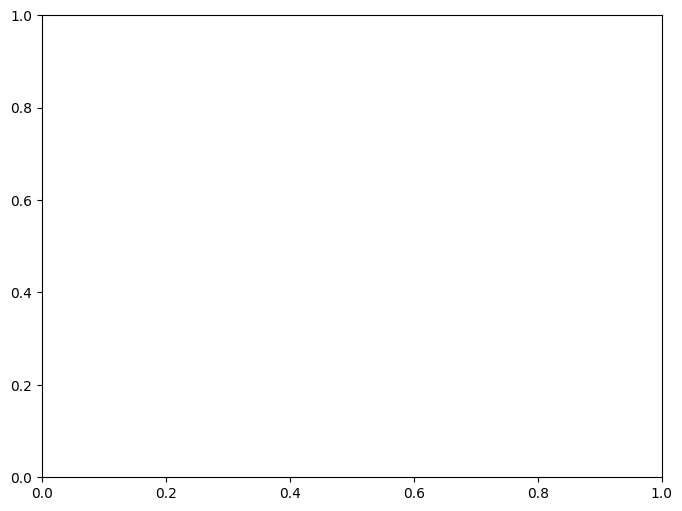

In [71]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(8, 6))

cset = tc.pale

# NSNS
bins = np.arange(0,20,2) 
delay_times_merged_NSNS_Gyr = delay_time_NSNS_all*(10**-3)
hist, bin_edges = np.histogram(delay_times_merged_NSNS_Gyr, weights=formation_efficiencies_NSNS, bins=bins, density=False)

bin_centers = (bin_edges[0:-1] + bin_edges[1:])/2
bin_widths = np.diff(bin_edges)

axs.plot(bin_centers, (hist/bin_widths)*1e6, color=cset.pale_green, lw=3, label='NSNS merged')
axs.set_xscale('log')

axs.set_ylabel(r'$\mathrm{\Delta} N/\mathrm{\Delta} t_{\mathrm{delay}} [\mathrm{Gyr^{-1}}10^6 \mathrm{M_\odot^{-1}}]$', fontsize=15)
# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=15)
axs.tick_params(axis='both', labelsize=15)
axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

Text(0.5, 1.0, 'Delay Time Distributions')

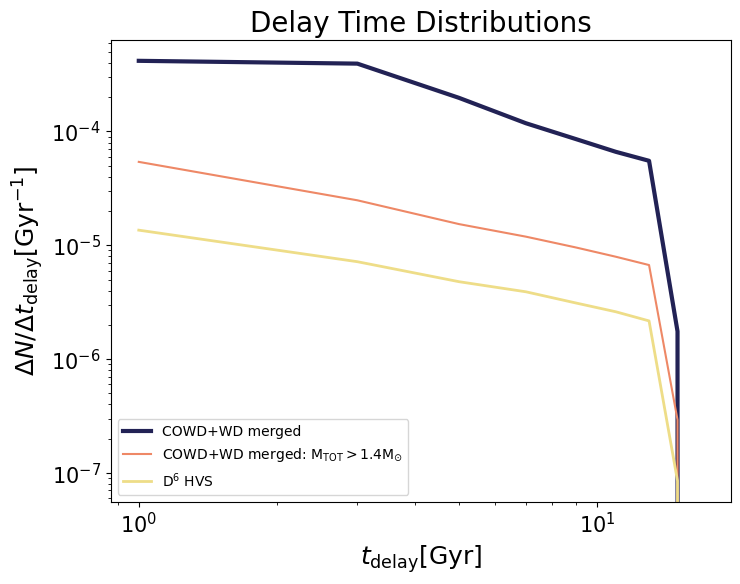

In [23]:
# plotting delay time dist
fig, axs = plt.subplots(figsize=(8, 6))

cset = tc.dark
cset_l = tc.light

# COWD+WD
bins_WDWD = np.arange(0,20,2)

delay_times_merged_WDWD_WDopt_Gyr = delay_times_merged_WDWD_WDopt*(10**-3)
hist_WDWD_WDopt, bin_edges_WDWD_WDopt = np.histogram(delay_times_merged_WDWD_WDopt_Gyr, weights=formation_efficiencies_COWD_WDopt, bins=bins_WDWD, density=False)

binwidth_WDWD = np.diff(bins_WDWD)
bin_centers_WDWD_WDopt = (bin_edges_WDWD_WDopt[0:-1] + bin_edges_WDWD_WDopt[1:])/2

axs.plot(bin_centers_WDWD_WDopt, (hist_WDWD_WDopt/binwidth_WDWD), color=cset.dark_blue, lw=3, label='COWD+WD merged')


# COWD+WD M_tot>1.4

delay_times_super_chan_WDWD_WDopt_Gyr = delay_times_super_chan_WDopt*(10**-3)
hist_WDWD_WDopt_super_chan, bin_edges_WDWD_WDopt_super_chan = np.histogram(delay_times_super_chan_WDWD_WDopt_Gyr, weights=formation_efficiencies_super_chan_WDopt, bins=bins_WDWD, density=False)

binwidth_WDWD = np.diff(bins_WDWD)
bin_centers_WDWD_WDopt_super_chan = (bin_edges_WDWD_WDopt_super_chan[0:-1] + bin_edges_WDWD_WDopt_super_chan[1:])/2

axs.plot(bin_centers_WDWD_WDopt_super_chan, (hist_WDWD_WDopt_super_chan/binwidth_WDWD), color=cset_l.orange,label=r'COWD+WD merged: $\rm{M_{TOT}}>1.4\rm{M_{\odot}}$')

# # D^6 - two star explosion

# bins_WDWD_D6_two = np.arange(0,20,2)

# delay_times_D6_two_Gyr = delay_times_D6_two*(10**-3)
# hist_D6_two, bin_edges_D6_two = np.histogram(delay_times_D6_two_Gyr, weights=mixture_weights_D6_two, bins=bins_WDWD_D6_two, density=False)

# binwidth_D6_two = np.diff(bins_WDWD_D6_two)
# bin_centers_D6_two = (bin_edges_D6_two[0:-1] + bin_edges_D6_two[1:])/2

# axs.plot(bin_centers_D6_two, (hist_D6_two/binwidth_D6_two), color=cset_l.light_blue, lw=2, ls='--', label='$\mathrm{D^6}$ Quadrupole Degenerate')


# # violent merger - unequal

# bins_WDWD_vm_unequal = np.arange(0,20,2)

# delay_times_violent_unequal_Gyr = delay_times_violent_unequal*(10**-3)
# hist_vm_unequal, bin_edges_vm_unequal = np.histogram(delay_times_violent_unequal_Gyr, weights=mixture_weights_violent_unequal, bins=bins_WDWD_vm_unequal, density=False)

# binwidth_vm_unequal = np.diff(bins_WDWD_vm_unequal)
# bin_centers_vm_unequal = (bin_edges_vm_unequal[0:-1] + bin_edges_vm_unequal[1:])/2

# axs.plot(bin_centers_vm_unequal, (hist_vm_unequal/binwidth_vm_unequal), color=cset_l.orange, lw=2, label='Violent Merger - Unequal')

# D^6 HVS

bins_WDWD_HVS = np.arange(0,20,2)

delay_times_HVS_Gyr = delay_times_HVS*(10**-3)
hist_HVS, bin_edges_HVS = np.histogram(delay_times_HVS_Gyr, weights=formation_eff_HVS, bins=bins_WDWD_HVS, density=False)

binwidth_HVS = np.diff(bins_WDWD_HVS)
bin_centers_HVS = (bin_edges_HVS[0:-1] + bin_edges_HVS[1:])/2

axs.plot(bin_centers_HVS, (hist_HVS/binwidth_HVS), color=cset_l.light_yellow, lw=2, label='$\mathrm{D^6}$ HVS')


# # violent merger - equal

# bins_WDWD_vm_equal = np.arange(0,20,2)

# delay_times_violent_equal_Gyr = delay_times_violent_equal*(10**-3)
# hist_vm_equal, bin_edges_vm_equal = np.histogram(delay_times_violent_equal_Gyr, weights=mixture_weights_violent_equal, bins=bins_WDWD_vm_equal, density=False)

# binwidth_vm_equal = np.diff(bins_WDWD_vm_equal)
# bin_centers_vm_equal = (bin_edges_vm_equal[0:-1] + bin_edges_vm_equal[1:])/2

# axs.plot(bin_centers_vm_equal, (hist_vm_equal/binwidth_vm_equal), color=cset_l.mint, lw=2, label='Violent Merger - Equal')






axs.set_ylabel(r'$\mathrm{\Delta} N/\mathrm{\Delta} t_{\mathrm{delay}} [\mathrm{Gyr^{-1}}]$', fontsize=18)
# axs[0].set_ylabel(r'Counts', fontsize=15)
axs.set_xlabel(r'$t_{\mathrm{delay}}[\mathrm{Gyr}]$', fontsize=18)
axs.tick_params(axis='both', labelsize=15)
axs.legend()

axs.set_yscale('log')
axs.set_xscale('log')
# axs.legend(loc='upper left')

axs.set_title('Delay Time Distributions', fontsize=20)

# plt.subplots_adjust(wspace=0.4) # add padding between plots

## save figure:
# plt.savefig("../figures/delay_time_dist_log.png",bbox_inches='tight',pad_inches=0.1)

### Close the data file

In [39]:
Data_NSNS.close()
Data_WDWD.close()